# EC1 - Web Scraping: ¿cuánto cuesta equipar un *home office* en Perú?

**Curso:** Adquisición y Curación de Datos
**Fuente:** Mercado Libre Perú — `https://listado.mercadolibre.com.pe`
**Técnicas:** Selenium (navegación dinámica) + BeautifulSoup (parseo del HTML)
**Fecha de ejecución:** ver salida de la celda de configuración

### Integrantes

| Nombre y apellidos | Código |
|---|---|
| *(completar)* | |
| *(completar)* | |
| *(completar)* | |
| *(completar)* | |

---

## 1. Objetivo y relevancia de la fuente

**Pregunta que guía la extracción:** ¿cuánto cuesta hoy, en soles, armar un puesto de
trabajo remoto completo en el Perú, y qué tan dispersos están los precios de cada componente?

**Por qué Mercado Libre Perú.** Es el marketplace de mayor tráfico del país y publica precios
de oferta reales, vigentes y en moneda local. No existe una fuente pública oficial con precios
minoristas de equipamiento tecnológico en el Perú, de modo que el dato solo puede obtenerse
observando el mercado. Los precios cambian a diario, por lo que la extracción automatizada es
la única forma razonable de capturar un corte transversal consistente en el tiempo.

**Unidad de observación:** la publicación (oferta) identificada por su código `MPE`.

**Componentes del *home office* que se recolectan:**

| Categoría | Rol en el puesto de trabajo |
|---|---|
| `laptops` | equipo principal de cómputo |
| `monitores` | pantalla externa |
| `sillas-de-oficina` | mobiliario / ergonomía |
| `teclados` | periférico de entrada |
| `mouse` | periférico de entrada |
| `audifonos` | audio para videollamadas |

**Restricción de la actividad:** no se utiliza ninguna API. Todo el dato proviene del HTML
renderizado por el navegador.

## 2. Instalación de dependencias

In [24]:
# Ejecutar una sola vez por entorno.
%pip install -q selenium beautifulsoup4 requests pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Configuración

Parámetros de la extracción en un solo lugar: fuente, categorías, límites y rutas de salida.

In [25]:
import random
import re
import time
import urllib.robotparser as robotparser
from datetime import datetime
from pathlib import Path
from urllib.parse import urlsplit, parse_qs

import pandas as pd
import requests
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

HOST = 'https://listado.mercadolibre.com.pe'

CATEGORIAS = {
    'laptops': HOST + '/laptops',
    'monitores': HOST + '/monitores',
    'sillas-de-oficina': HOST + '/sillas-de-oficina',
    'teclados': HOST + '/teclados',
    'mouse': HOST + '/mouse',
    'audifonos': HOST + '/audifonos',
}

USER_AGENT = (
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
    '(KHTML, like Gecko) Chrome/152.0.0.0 Safari/537.36'
)
HEADERS = {'User-Agent': USER_AGENT, 'Accept-Language': 'es-PE,es;q=0.9'}

MAX_PAGINAS = 10      # páginas de resultados por categoría
TIMEOUT = 25          # segundos máximos de espera por elemento
PAUSA_MINIMA = 5      # segundos entre peticiones si robots.txt no declara Crawl-delay

# El notebook corre tanto desde /notebooks como desde la raíz del repo o desde Colab.
BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DIR_DATOS = BASE / 'datos'
DIR_GRAFICOS = BASE / 'graficos'
for carpeta in (DIR_DATOS, DIR_GRAFICOS):
    carpeta.mkdir(parents=True, exist_ok=True)

RUTA_CRUDO = DIR_DATOS / 'homeoffice_ml_crudo.csv'
RUTA_LIMPIO = DIR_DATOS / 'homeoffice_ml_limpio.csv'
RUTA_MUESTRA_HTML = DIR_DATOS / 'muestra_tarjeta.html'

# Perfil de Chrome persistente: una vez que se completa el inicio de sesion manual, la sesion
# queda guardada aqui y las siguientes ejecuciones no vuelven a pedir el muro de verificacion.
PERFIL_CHROME = BASE / '.perfil_chrome'

COLUMNAS = [
    'categoria', 'pagina', 'posicion_pagina', 'id_publicacion', 'titulo',
    'moneda', 'precio_actual_texto', 'precio_anterior_texto', 'descuento_texto',
    'cuotas_texto', 'vendedor_texto', 'envio_texto', 'resenas_texto',
    'etiqueta_texto', 'url_publicacion', 'url_fuente', 'fecha_extraccion',
]

print('Inicio de la sesión:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Categorías a extraer:', len(CATEGORIAS))
print('Páginas máximas por categoría:', MAX_PAGINAS)
print('Carpeta de datos:', DIR_DATOS)

Inicio de la sesión: 2026-09-15 23:34:32
Categorías a extraer: 6
Páginas máximas por categoría: 10
Carpeta de datos: c:\Users\yared\Documents\ACD\sem6\EC1-scraping\ec1-scraping-mercadolibre\datos


## 4. Verificación de `robots.txt` antes de extraer

El scraping responsable empieza por leer las reglas del sitio. Se descarga el `robots.txt` del
host de listados y se consulta **ruta por ruta** con `urllib.robotparser` (biblioteca estándar).
Si alguna categoría estuviera prohibida, la celda detiene la ejecución.

También se respeta el `Crawl-delay` declarado por el sitio como pausa entre peticiones.

In [26]:
def cargar_robots(host):
    # Se descarga con requests y se usa .parse() en lugar de .read(): el sitio responde 403 al
    # user-agent por defecto de urllib, y ante un 403 RobotFileParser asume "todo prohibido".
    respuesta = requests.get(host + '/robots.txt', headers=HEADERS, timeout=30)
    respuesta.raise_for_status()
    parser = robotparser.RobotFileParser()
    parser.parse(respuesta.text.splitlines())
    return parser, respuesta.text


ROBOTS, TEXTO_ROBOTS = cargar_robots(HOST)

declarado = ROBOTS.crawl_delay(USER_AGENT)
PAUSA = float(declarado) if declarado else float(PAUSA_MINIMA)

permisos = pd.DataFrame(
    [{'categoria': nombre, 'url': url, 'permitido_por_robots': ROBOTS.can_fetch(USER_AGENT, url)}
     for nombre, url in CATEGORIAS.items()]
)

print('robots.txt descargado:', len(TEXTO_ROBOTS), 'caracteres')
print('Crawl-delay declarado para nuestro user-agent:', declarado)
print('Pausa que aplicaremos entre páginas:', PAUSA, 'segundos')
display(permisos)

assert permisos['permitido_por_robots'].all(), 'Hay rutas bloqueadas por robots.txt: no se extraen.'
print('\nTodas las rutas solicitadas están permitidas por robots.txt.')

robots.txt descargado: 11222 caracteres
Crawl-delay declarado para nuestro user-agent: None
Pausa que aplicaremos entre páginas: 5.0 segundos


,categoria,url,permitido_por_robots
0,laptops,https://listado.mercadolibre.com.pe/laptops,True
1,monitores,https://listado.mercadolibre.com.pe/monitores,True
2,sillas-de-oficina,https://listado.mercadolibre.com.pe/sillas-de-...,True
3,teclados,https://listado.mercadolibre.com.pe/teclados,True
4,mouse,https://listado.mercadolibre.com.pe/mouse,True
5,audifonos,https://listado.mercadolibre.com.pe/audifonos,True



Todas las rutas solicitadas están permitidas por robots.txt.


### Nota ética

Mercado Libre bloquea en su `robots.txt` a los rastreadores de modelos de lenguaje
(`GPTBot`, `ClaudeBot`, `PerplexityBot`, `Amazonbot`) con `Disallow: /`, pero **permite** el
acceso a las rutas de listado para agentes genéricos. Esta extracción se limita a esas rutas
permitidas, con una pausa entre peticiones, un volumen acotado (10 páginas por categoría) y
fines exclusivamente académicos. No se recolectan datos personales: todos los campos son
atributos públicos de una publicación comercial.

Mercado Libre también corre un sistema propio de detección de fraude/automatización (incluye
reCAPTCHA Enterprise) que puede mostrar una pantalla de verificación de cuenta a una sesión de
Selenium aunque la ruta visitada ya esté permitida por `robots.txt`. Este notebook **no intenta
sortear ese sistema**: cuando aparece, `ejecutar_scraper` se detiene con `input()` y espera a
que una persona lo resuelva a mano en la ventana de Chrome antes de continuar (ver sección 8).
Automatizar la resolución de un CAPTCHA o imitar más de cerca a un usuario para evadir ese
sistema queda fuera del alcance ético de este trabajo.

## 5. Evidencia: por qué esta fuente exige Selenium y no basta `requests`

Antes de elegir la herramienta, se comprueba el problema. Se pide la misma URL con `requests`
(HTTP puro, sin ejecutar JavaScript) y se cuenta cuántas tarjetas de producto aparecen.

In [27]:
SELECTORES_TARJETA = ['li.ui-search-layout__item', 'div.poly-card', 'div.ui-search-result__wrapper']


def detectar_tarjetas(soup):
    for selector in SELECTORES_TARJETA:
        tarjetas = soup.select(selector)
        if tarjetas:
            return tarjetas
    return []


url_prueba = CATEGORIAS['laptops']
respuesta_estatica = requests.get(url_prueba, headers=HEADERS, timeout=TIMEOUT)
soup_estatico = BeautifulSoup(respuesta_estatica.text, 'html.parser')

print('URL evaluada:', url_prueba)
print('Código HTTP:', respuesta_estatica.status_code)
print('Tamaño del HTML recibido:', len(respuesta_estatica.text), 'caracteres')
print('Tarjetas de producto halladas SIN ejecutar JavaScript:', len(detectar_tarjetas(soup_estatico)))
print()
print('Conclusión: el servidor responde 200 pero entrega un documento sin resultados; el listado')
print('se construye en el navegador. Por eso la extracción usa Selenium para renderizar la página')
print('y BeautifulSoup para parsear el HTML ya renderizado.')

URL evaluada: https://listado.mercadolibre.com.pe/laptops
Código HTTP: 200
Tamaño del HTML recibido: 25247 caracteres
Tarjetas de producto halladas SIN ejecutar JavaScript: 0

Conclusión: el servidor responde 200 pero entrega un documento sin resultados; el listado
se construye en el navegador. Por eso la extracción usa Selenium para renderizar la página
y BeautifulSoup para parsear el HTML ya renderizado.


## 6. Parseo del HTML con BeautifulSoup

Cada tarjeta de producto se convierte en una fila. El parser prueba varios nombres de clase por
campo, porque Mercado Libre convive con dos plantillas (`poly-*` y `ui-search-*`); si un campo no
existe en la tarjeta se guarda `None` en lugar de inventar un valor.

In [28]:
# Cada campo se busca por una lista de clases candidatas, en orden de preferencia.
SELECTORES_CAMPO = {
    'titulo': ['poly-component__title', 'ui-search-item__title'],
    'cuotas_texto': ['poly-price__installments', 'ui-search-installments'],
    'vendedor_texto': ['poly-component__seller', 'ui-search-official-store-label'],
    'envio_texto': ['poly-component__shipping-v2', 'poly-component__shipping', 'ui-search-item__shipping'],
    'resenas_texto': ['poly-component__review-compacted', 'poly-reviews', 'poly-component__reviews', 'ui-search-reviews'],
    'etiqueta_texto': ['poly-component__highlight', 'ui-search-item__highlight-label'],
    'descuento_texto': ['poly-price__discount-polylabel', 'andes-money-amount__discount', 'ui-search-price__discount'],
}


def primera_clase(raiz, clases):
    for clase in clases:
        elemento = raiz.find(class_=clase)
        if elemento is not None:
            return elemento
    return None


def texto_de(elemento):
    if elemento is None:
        return None
    contenido = elemento.get_text(' ', strip=True)
    return contenido if contenido else None


def texto_precio(bloque):
    # Mercado Libre parte el precio en símbolo, entero y centavos; se recompone tal como se ve.
    if bloque is None:
        return None
    simbolo = primera_clase(bloque, ['andes-money-amount__currency-symbol'])
    entero = primera_clase(bloque, ['andes-money-amount__fraction'])
    centavos = primera_clase(bloque, ['andes-money-amount__cents'])
    if entero is None:
        return texto_de(bloque)
    valor = texto_de(entero)
    if centavos is not None:
        valor = valor + ',' + texto_de(centavos)
    if simbolo is not None:
        valor = texto_de(simbolo) + ' ' + valor
    return valor


def extraer_id(texto):
    # El código de publicación (MPE + dígitos) viaja en la URL y en atributos de la tarjeta.
    encontrado = re.search(r'MPE[-_]?(\d{6,})', (texto or '').upper())
    return 'MPE' + encontrado.group(1) if encontrado else None


def procesar_html(html, categoria, pagina, url_fuente):
    soup = BeautifulSoup(html, 'html.parser')
    tarjetas = detectar_tarjetas(soup)
    momento = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    filas = []

    for posicion, tarjeta in enumerate(tarjetas, start=1):
        titulo = primera_clase(tarjeta, SELECTORES_CAMPO['titulo'])
        enlace = titulo if (titulo is not None and titulo.name == 'a') else tarjeta.find('a', href=True)
        url_publicacion = enlace.get('href') if enlace is not None else None

        precio_actual = primera_clase(tarjeta, ['poly-price__current', 'ui-search-price__second-line'])
        precio_anterior = primera_clase(tarjeta, ['andes-money-amount--previous', 'ui-search-price__original-value'])
        simbolo = primera_clase(precio_actual or tarjeta, ['andes-money-amount__currency-symbol'])
        descuento = primera_clase(tarjeta, SELECTORES_CAMPO['descuento_texto'])

        fila = {
            'categoria': categoria,
            'pagina': pagina,
            'posicion_pagina': posicion,
            'id_publicacion': extraer_id((url_publicacion or '') + ' ' + str(tarjeta)),
            'titulo': texto_de(titulo),
            'moneda': texto_de(simbolo),
            'precio_actual_texto': texto_precio(precio_actual),
            'precio_anterior_texto': texto_precio(precio_anterior),
            'descuento_texto': texto_de(descuento),
            'url_publicacion': url_publicacion,
            'url_fuente': url_fuente,
            'fecha_extraccion': momento,
        }
        for campo in ['cuotas_texto', 'vendedor_texto', 'envio_texto', 'resenas_texto', 'etiqueta_texto']:
            fila[campo] = texto_de(primera_clase(tarjeta, SELECTORES_CAMPO[campo]))

        filas.append(fila)

    return filas

## 7. Navegación dinámica con Selenium

Selenium abre Chrome, espera a que las tarjetas existan en el DOM (`WebDriverWait`, no `sleep`
a ciegas) y avanza usando el enlace real *Siguiente* que publica el sitio, en lugar de construir
URLs de paginación a mano.

In [29]:
def crear_driver(headless=False):
    # Se usa webdriver-manager en lugar de un chromedriver fijo en PATH: descarga la version
    # exacta que corresponde al Chrome instalado, evitando el SessionNotCreatedException que
    # aparece cuando Chrome se actualiza y el chromedriver.exe guardado localmente queda viejo.
    from selenium.webdriver.chrome.service import Service
    from webdriver_manager.chrome import ChromeDriverManager

    opciones = Options()
    opciones.add_argument('--start-maximized')
    opciones.add_argument('--lang=es-PE')
    opciones.add_argument('--user-agent=' + USER_AGENT)
    opciones.add_argument('--user-data-dir=' + str(PERFIL_CHROME))
    if headless:
        opciones.add_argument('--headless=new')

    # El muro de "verificacion de cuenta" no protege contenido (las rutas ya estan permitidas
    # por robots.txt): aparece porque el sitio detecta que el navegador esta controlado por
    # Selenium (navegando de forma manual, sin estas senales, no se pide nada). Se retiran la
    # bandera navigator.webdriver y el aviso "Chrome esta siendo controlado por un software de
    # pruebas automatizado" para que el navegador se comporte como una sesion normal.
    opciones.add_argument('--disable-blink-features=AutomationControlled')
    opciones.add_experimental_option('excludeSwitches', ['enable-automation', 'enable-logging'])
    opciones.add_experimental_option('useAutomationExtension', False)

    servicio = Service(ChromeDriverManager().install())
    driver = webdriver.Chrome(service=servicio, options=opciones)
    driver.execute_cdp_cmd('Page.addScriptToEvaluateOnNewDocument', {
        'source': "Object.defineProperty(navigator, 'webdriver', {get: () => undefined})"
    })
    return driver


def esperar_resultados(driver):
    # Condición explícita: seguimos solo cuando el listado ya está en el DOM.
    WebDriverWait(driver, TIMEOUT).until(
        EC.presence_of_element_located((By.CSS_SELECTOR, ', '.join(SELECTORES_TARJETA)))
    )


def ir_a_siguiente(driver):
    # La paginación vive al final del listado y Mercado Libre solo la renderiza cuando se llega
    # ahí: sin bajar primero, find_elements no encuentra el control y el scraper concluye que la
    # categoría se acabó en la página 1.
    for _ in range(3):
        driver.execute_script('window.scrollTo(0, document.body.scrollHeight);')
        time.sleep(1)

    selectores = [
        'li.andes-pagination__button--next a',
        '.andes-pagination__button--next a',
        'a[title="Siguiente"]',
        'a[aria-label="Siguiente"]',
        'button[aria-label="Siguiente"]',
    ]
    candidatos = []
    for selector in selectores:
        candidatos.extend(driver.find_elements(By.CSS_SELECTOR, selector))

    if not candidatos:
        # Respaldo por texto visible, por si cambian las clases y los atributos del control.
        for elemento in driver.find_elements(By.CSS_SELECTOR, 'a, button'):
            etiquetas = (elemento.text, elemento.get_attribute('title'),
                         elemento.get_attribute('aria-label'))
            if any('siguiente' in (valor or '').lower() for valor in etiquetas):
                candidatos.append(elemento)

    for elemento in candidatos:
        href = elemento.get_attribute('href')
        if href:
            driver.get(href)
            return True

        # Controles sin href: se hace clic por JavaScript porque el botón suele quedar tapado
        # por banners flotantes y un clic normal falla con ElementClickInterceptedException.
        url_previa = driver.current_url
        try:
            driver.execute_script('arguments[0].click();', elemento)
            WebDriverWait(driver, TIMEOUT).until(EC.url_changes(url_previa))
            return True
        except Exception:
            continue

    return False


def hay_muro_de_acceso(driver):
    actual = (driver.current_url or '').lower()
    return any(marca in actual for marca in ['/login', '/lgz/', 'account-verification'])


def esperar_resolucion_manual(driver, minutos_maximo=10):
    # input() depende de que el frontend del notebook capture stdin correctamente, y eso no
    # siempre funciona (el cuadro de texto puede no aparecer visible en VS Code/Jupyter). En vez
    # de bloquear ahi, se sondea la URL del navegador: en cuanto la persona resuelve el login o
    # el captcha a mano y el sitio redirige fuera de /login, /lgz/ o account-verification, el
    # scraper lo detecta solo y continua sin necesitar que se presione Enter en ningun cuadro.
    print('Mercado Libre pide iniciar sesión o verificar el acceso.')
    print(f'Resuélvelo en la ventana de Chrome; el scraper detecta solo cuando termines '
          f'(reintenta cada 3 s, hasta {minutos_maximo} min).')
    limite = time.time() + minutos_maximo * 60
    while time.time() < limite:
        if not hay_muro_de_acceso(driver):
            print('Acceso resuelto, continuando la extracción...')
            return True
        time.sleep(3)
    return False

## 8. Ejecución del scraping

Recorre cada categoría, guarda cada página en el CSV crudo apenas se extrae (si la sesión se
corta, lo ya recolectado no se pierde) y respeta la pausa entre peticiones. Guarda además el HTML
de una tarjeta como evidencia del origen del dato.

In [30]:
def ejecutar_scraper(headless=False):
    driver = crear_driver(headless=headless)
    registros, primera_escritura, muestra_guardada = 0, True, False
    bitacora = []

    try:
        for categoria, url_inicial in CATEGORIAS.items():
            driver.get(url_inicial)
            url_pagina = url_inicial

            for pagina in range(1, MAX_PAGINAS + 1):
                try:
                    esperar_resultados(driver)
                except Exception:
                    if hay_muro_de_acceso(driver):
                        if not esperar_resolucion_manual(driver):
                            raise RuntimeError(
                                'No se resolvió el acceso manual dentro del tiempo esperado.'
                            )
                        driver.get(url_pagina)
                        esperar_resultados(driver)
                    else:
                        print(f'[{categoria}] página {pagina}: no cargaron resultados, se corta la categoría.')
                        break

                html = driver.page_source
                filas = procesar_html(html, categoria, pagina, driver.current_url)

                if not filas:
                    print(f'[{categoria}] página {pagina}: sin tarjetas, fin de la categoría.')
                    break

                if not muestra_guardada:
                    soup = BeautifulSoup(html, 'html.parser')
                    RUTA_MUESTRA_HTML.write_text(str(detectar_tarjetas(soup)[0]), encoding='utf-8')
                    muestra_guardada = True

                pd.DataFrame(filas, columns=COLUMNAS).to_csv(
                    RUTA_CRUDO, mode='w' if primera_escritura else 'a',
                    header=primera_escritura, index=False, encoding='utf-8-sig',
                )
                primera_escritura = False
                registros += len(filas)
                bitacora.append({'categoria': categoria, 'pagina': pagina,
                                 'tarjetas': len(filas), 'url': driver.current_url})
                print(f'[{categoria}] página {pagina}: {len(filas)} tarjetas | acumulado: {registros}')

                if pagina == MAX_PAGINAS:
                    break

                # ir_a_siguiente deja el navegador ya en la página siguiente, así que el ciclo
                # no vuelve a hacer driver.get(): solo registra dónde quedó por si hay que
                # recargar tras un muro de acceso.
                if not ir_a_siguiente(driver):
                    print(f'[{categoria}] no hay página siguiente.')
                    break
                url_pagina = driver.current_url
                time.sleep(PAUSA)

    finally:
        driver.quit()

    if registros == 0:
        raise RuntimeError('No se extrajo ningún registro.')

    print('\nExtracción finalizada. Registros crudos:', registros)
    return pd.read_csv(RUTA_CRUDO), pd.DataFrame(bitacora)

In [31]:
crudo, bitacora = ejecutar_scraper(headless=False)
print('Dimensiones del dataset crudo:', crudo.shape)
display(bitacora.head(12))
display(crudo.head(10))

[laptops] página 1: 48 tarjetas | acumulado: 48
[laptops] página 2: 48 tarjetas | acumulado: 96
[laptops] página 3: 48 tarjetas | acumulado: 144
[laptops] página 4: 48 tarjetas | acumulado: 192
[laptops] página 5: 48 tarjetas | acumulado: 240
[laptops] página 6: 48 tarjetas | acumulado: 288
[laptops] página 7: 48 tarjetas | acumulado: 336
[laptops] página 8: 48 tarjetas | acumulado: 384
[laptops] página 9: 48 tarjetas | acumulado: 432
[laptops] página 10: 48 tarjetas | acumulado: 480
[monitores] página 1: 52 tarjetas | acumulado: 532
[monitores] página 2: 52 tarjetas | acumulado: 584
[monitores] página 3: 52 tarjetas | acumulado: 636
[monitores] página 4: 52 tarjetas | acumulado: 688
[monitores] página 5: 52 tarjetas | acumulado: 740
[monitores] página 6: 52 tarjetas | acumulado: 792
[monitores] página 7: 52 tarjetas | acumulado: 844
[monitores] página 8: 52 tarjetas | acumulado: 896
[monitores] página 9: 52 tarjetas | acumulado: 948
[monitores] página 10: 52 tarjetas | acumulado: 1000

,categoria,pagina,tarjetas,url
0,laptops,1,48,https://listado.mercadolibre.com.pe/laptops
1,laptops,2,48,https://listado.mercadolibre.com.pe/computacio...
2,laptops,3,48,https://listado.mercadolibre.com.pe/computacio...
3,laptops,4,48,https://listado.mercadolibre.com.pe/computacio...
4,laptops,5,48,https://listado.mercadolibre.com.pe/computacio...
5,laptops,6,48,https://listado.mercadolibre.com.pe/computacio...
6,laptops,7,48,https://listado.mercadolibre.com.pe/computacio...
7,laptops,8,48,https://listado.mercadolibre.com.pe/computacio...
8,laptops,9,48,https://listado.mercadolibre.com.pe/computacio...
9,laptops,10,48,https://listado.mercadolibre.com.pe/computacio...


,categoria,pagina,posicion_pagina,id_publicacion,titulo,moneda,precio_actual_texto,precio_anterior_texto,descuento_texto,cuotas_texto,vendedor_texto,envio_texto,resenas_texto,etiqueta_texto,url_publicacion,url_fuente,fecha_extraccion
0,laptops,1,1,MPE64140599,"Laptop HP 15-fd0255la, Intel Core i5, 8 GB RAM...",S/,S/ 2.199,S/ 2.999,26% OFF,"18 cuotas de S/ 122 , 17 sin interés",Mercado Libre,Llega gratis mañana,4.7 | +50 vendidos,NaN,https://www.mercadolibre.com.pe/laptop-hp-15-f...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
1,laptops,1,2,MPE65867513,Lenovo Loq 15iax9 Core I5 12450hx 16gb 512gb R...,S/,S/ 3.299,S/ 3.890,15% OFF,"6 cuotas de S/ 549 , 83 sin interés",PC YA Empresarial,Llega gratis mañana,4.8 | +25 vendidos,NaN,https://www.mercadolibre.com.pe/lenovo-loq-15i...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
2,laptops,1,3,MPE66346869,Asus Tuf Gaming F16 (2025) Core I7 14650hx 32g...,S/,S/ 6.699,S/ 10.199,34% OFF,6 cuotas de S/ 1.116 sin interés,LaptopShop,Llega gratis mañana,4.7 | +25 vendidos,NaN,https://www.mercadolibre.com.pe/asus-tuf-gamin...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
3,laptops,1,4,MPE76077395,"Laptop HP AI 15-fd2369la, Intel Core Ultra 5, ...",S/,S/ 2.909,S/ 3.550,18% OFF,"6 cuotas de S/ 484 , 83 sin interés",HP Store,Llega gratis mañana,NaN,NaN,https://www.mercadolibre.com.pe/laptop-hp-ai-1...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
4,laptops,1,5,MPE28100188,Notebook Lenovo V15 G4 Amd Ryzen 5 7520u 8gb S...,S/,S/ 1.889,S/ 2.190,13% OFF,"6 cuotas de S/ 314 , 83 sin interés",PC YA Empresarial,Llega gratis mañana,4.7 | +25 vendidos,NaN,https://www.mercadolibre.com.pe/notebook-lenov...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
5,laptops,1,6,MPE75623894,Lenovo Loq 15iax9 Core I5 12450hx 16gb 512gb R...,S/,S/ 3.299,NaN,NaN,"6 cuotas de S/ 549 , 83 sin interés",NaN,Envío gratis Envío gratis,NaN,NaN,https://www.mercadolibre.com.pe/lenovo-loq-15i...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
6,laptops,1,7,MPE1066159881,Macbook Air Mdhe4e/a Midnight 512gb 16 Gb Ram ...,S/,S/ 5.549,S/ 6.999,20% OFF,"6 cuotas de S/ 924 , 83 sin interés",Apple,Llega gratis mañana,4.8 | +50 vendidos,NaN,https://www.mercadolibre.com.pe/macbook-air-md...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
7,laptops,1,8,MPE41268256,Notebook Lenovo V15 G4 Amd Ryzen 3 7320u Ram 8...,S/,S/ 1.699,NaN,NaN,"6 cuotas de S/ 283 , 17 sin interés",NaN,Llega gratis mañana,NaN,NaN,https://www.mercadolibre.com.pe/notebook-lenov...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
8,laptops,1,9,MPE66172746,"Apple 2026 Macbook Neo (de 13 Pulgadas, Chip A...",S/,S/ 3.899,S/ 4.999,22% OFF,"6 cuotas de S/ 649 , 83 sin interés",MASPLAY.PE,Llega gratis mañana,4.9 | +25 vendidos,NaN,https://www.mercadolibre.com.pe/apple-2026-mac...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39
9,laptops,1,10,MPE57422353,Lenovo Legion 5 2025 Ultra 9 275hx 32gb 2tb Rt...,S/,S/ 8.959,S/ 11.945,25% OFF,6 cuotas de S/ 1.493 sin interés,NaN,Llega gratis mañana,4.9 | +25 vendidos,NaN,https://www.mercadolibre.com.pe/lenovo-legion-...,https://listado.mercadolibre.com.pe/laptops,2026-09-15 23:34:39


## 9. Diagnóstico de la extracción

Dos controles. Primero, cobertura: qué porcentaje de cada campo quedó vacío. Segundo, las clases
CSS realmente presentes en una tarjeta: si Mercado Libre renombra una clase, este listado muestra
cuál usar y el parser se corrige sin adivinar.

In [32]:
cobertura = pd.DataFrame({
    'columna': crudo.columns,
    'nulos': [crudo[c].isna().sum() for c in crudo.columns],
    'porcentaje_nulos': [round(crudo[c].isna().mean() * 100, 2) for c in crudo.columns],
    'valores_distintos': [crudo[c].nunique(dropna=True) for c in crudo.columns],
}).sort_values('porcentaje_nulos', ascending=False)

print('Registros crudos:', len(crudo))
print('Atributos por registro:', crudo.shape[1])
print('Publicaciones únicas:', crudo['id_publicacion'].nunique(dropna=True))
print('Filas con id repetido:', int(crudo.duplicated('id_publicacion', keep=False).sum()))
display(cobertura)
display(crudo['categoria'].value_counts())

Registros crudos: 3680
Atributos por registro: 17
Publicaciones únicas: 2936
Filas con id repetido: 875


,columna,nulos,porcentaje_nulos,valores_distintos
13,etiqueta_texto,3680,100.00,0
12,resenas_texto,2224,60.43,53
10,vendedor_texto,2087,56.71,98
8,descuento_texto,1660,45.11,66
7,precio_anterior_texto,1660,45.11,815
11,envio_texto,236,6.41,3
9,cuotas_texto,143,3.89,1738
15,url_fuente,0,0.00,60
14,url_publicacion,0,0.00,3680
0,categoria,0,0.00,6


categoria
teclados             680
mouse                680
audifonos            680
sillas-de-oficina    640
monitores            520
laptops              480
Name: count, dtype: int64

In [33]:
from collections import Counter

tarjeta_muestra = BeautifulSoup(RUTA_MUESTRA_HTML.read_text(encoding='utf-8'), 'html.parser')
clases = Counter(c for el in tarjeta_muestra.find_all(class_=True) for c in el.get('class'))

print('Clases CSS presentes en una tarjeta real (útil si un campo quedó 100% nulo):')
for clase, veces in sorted(clases.items()):
    print(f'  {clase}  x{veces}')

Clases CSS presentes en una tarjeta real (útil si un campo quedó 100% nulo):
  andes-card  x1
  andes-card--flat  x1
  andes-card--padding-0  x1
  andes-card--primary  x1
  andes-money-amount  x3
  andes-money-amount--cents-comma  x2
  andes-money-amount--cents-superscript  x1
  andes-money-amount--previous  x1
  andes-money-amount__cents  x1
  andes-money-amount__currency  x3
  andes-money-amount__currency-symbol  x3
  andes-money-amount__fraction  x3
  andes-visually-hidden  x1
  poly-bookmark__btn  x1
  poly-bookmark__icon-empty  x1
  poly-bookmark__icon-full  x1
  poly-card  x1
  poly-card--CORE  x1
  poly-card--grid-card  x1
  poly-card--xlarge  x1
  poly-card__content  x1
  poly-card__portada  x1
  poly-component__bookmark  x1
  poly-component__image-overlay  x1
  poly-component__picture  x1
  poly-component__price  x1
  poly-component__review-compacted  x1
  poly-component__seller  x1
  poly-component__shipping-v2  x1
  poly-component__title  x1
  poly-component__title-wrapper  

## 10. Estructuración del dataset

Se convierten los textos observados a tipos utilizables: precios a número, cuotas a entero y
monto, reseñas a calificación y cantidad de opiniones, envío a indicador booleano. Se conservan
los textos originales para poder auditar cada conversión. La deduplicación mantiene una
observación por publicación.

In [34]:
def a_numero(texto):
    # Formato peruano: el punto separa miles y la coma los decimales (S/ 4.849,90 -> 4849.90).
    if not isinstance(texto, str):
        return None
    limpio = re.sub(r'[^\d.,]', '', texto)
    if not limpio:
        return None
    try:
        return float(limpio.replace('.', '').replace(',', '.'))
    except ValueError:
        return None


def numero_de_cuotas(texto):
    if not isinstance(texto, str):
        return None
    encontrado = re.search(r'(\d+)\s*cuotas', texto, flags=re.IGNORECASE)
    return int(encontrado.group(1)) if encontrado else None


def monto_de_cuota(texto):
    # Se toma solo la cifra posterior a "cuotas de": a_numero() sobre el texto completo
    # pegaría el número de cuotas al monto (12 cuotas de S/ 208,32 -> 12208.32).
    if not isinstance(texto, str):
        return None
    encontrado = re.search(r'cuotas\s+de\s+[^\d]*([\d.,]+)', texto, flags=re.IGNORECASE)
    return a_numero(encontrado.group(1)) if encontrado else None


def calificacion(texto):
    if not isinstance(texto, str):
        return None
    encontrado = re.search(r'(\d[.,]\d)', texto)
    return float(encontrado.group(1).replace(',', '.')) if encontrado else None


def cantidad_opiniones(texto):
    if not isinstance(texto, str):
        return None
    encontrado = re.search(r'\(\s*(\d+)\s*\)', texto)
    return int(encontrado.group(1)) if encontrado else None


df = crudo.copy()
for columna in df.select_dtypes(include='object').columns:
    df[columna] = df[columna].str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)

df['precio'] = df['precio_actual_texto'].map(a_numero)
df['precio_anterior'] = df['precio_anterior_texto'].map(a_numero)
df['numero_cuotas'] = df['cuotas_texto'].map(numero_de_cuotas)
df['monto_cuota'] = df['cuotas_texto'].map(monto_de_cuota)
df['calificacion'] = df['resenas_texto'].map(calificacion)
df['opiniones'] = df['resenas_texto'].map(cantidad_opiniones)
# .astype('string') antes de .str: si el selector de envio no matchea ninguna tarjeta la columna
# queda 100% nula y pandas la infiere como float64 al leer el CSV, con lo que .str.contains
# revienta con "Can only use .str accessor with string values!" en vez de devolver solo False.
df['envio_gratis'] = df['envio_texto'].astype('string').str.contains('gratis', case=False, na=False)
df['ofrece_cuotas'] = df['numero_cuotas'].notna()
df['fecha_extraccion'] = pd.to_datetime(df['fecha_extraccion'])

antes = len(df)
df = df[df['id_publicacion'].notna() & df['titulo'].notna() & df['precio'].gt(0)]
sin_esenciales = antes - len(df)

antes = len(df)
df = df.sort_values('fecha_extraccion').drop_duplicates('id_publicacion', keep='last')
duplicados_retirados = antes - len(df)

limpio = df[[
    'id_publicacion', 'categoria', 'titulo', 'moneda', 'precio', 'precio_anterior',
    'numero_cuotas', 'monto_cuota', 'ofrece_cuotas', 'envio_gratis', 'calificacion',
    'opiniones', 'vendedor_texto', 'pagina', 'posicion_pagina', 'url_publicacion',
    'fecha_extraccion',
]].reset_index(drop=True)

limpio.to_csv(RUTA_LIMPIO, index=False, encoding='utf-8-sig')

print('Filas sin campos esenciales descartadas:', sin_esenciales)
print('Publicaciones duplicadas retiradas:', duplicados_retirados)
print('Dataset final:', limpio.shape)
print('Archivo:', RUTA_LIMPIO)
display(limpio.head(10))

Filas sin campos esenciales descartadas: 0
Publicaciones duplicadas retiradas: 744
Dataset final: (2936, 17)
Archivo: c:\Users\yared\Documents\ACD\sem6\EC1-scraping\ec1-scraping-mercadolibre\datos\homeoffice_ml_limpio.csv


,id_publicacion,categoria,titulo,moneda,precio,precio_anterior,numero_cuotas,monto_cuota,ofrece_cuotas,envio_gratis,calificacion,opiniones,vendedor_texto,pagina,posicion_pagina,url_publicacion,fecha_extraccion
0,MPE74158401,laptops,"MacBook Pro 16 pulgadas, M5 Pro, 18 CPU, 20 GP...",S/,15999.0,NaN,12.0,1333.0,True,True,NaN,None,NaN,1,27,https://www.mercadolibre.com.pe/macbook-pro-16...,2026-09-15 23:34:39
1,MPE60293850,laptops,Lenovo Yoga 7 gen 10 2 en 1,S/,5399.0,NaN,6.0,899.0,True,True,4.8,None,NaN,1,28,https://www.mercadolibre.com.pe/lenovo-yoga-7-...,2026-09-15 23:34:39
2,MPE66159894,laptops,"MacBook Air de 15 pulgadas: chip M5, CPU de 10...",S/,6999.0,NaN,6.0,1166.0,True,True,4.9,None,NaN,1,29,https://www.mercadolibre.com.pe/macbook-air-de...,2026-09-15 23:34:39
3,MPE38037406,laptops,Laptop Lenovo Athlon Silver 7120u 8gb Ssd 256g...,S/,1459.0,1890.0,6.0,243.0,True,True,NaN,None,PC YA Empresarial,1,30,https://www.mercadolibre.com.pe/laptop-lenovo-...,2026-09-15 23:34:39
4,MPE70300212,laptops,"Laptop HP 15-fc0372la, AMD Ryzen 7, 16 GB RAM,...",S/,2659.0,4499.0,6.0,443.0,True,True,NaN,None,HP Store,1,31,https://www.mercadolibre.com.pe/laptop-hp-15-f...,2026-09-15 23:34:39
5,MPE62909143,laptops,Laptop Asus Zenbook A14 X X1 26 16gb Ram 1tb W...,S/,4399.0,6129.0,6.0,733.0,True,True,NaN,None,Asus,1,32,https://www.mercadolibre.com.pe/laptop-asus-ze...,2026-09-15 23:34:39
6,MPE64073337,laptops,Notebook Hp 15-fd2350la Intel Ultra 5 8gb 512 ...,S/,2999.0,3999.0,6.0,499.0,True,True,NaN,None,Tiendas EFE,1,33,https://www.mercadolibre.com.pe/notebook-hp-15...,2026-09-15 23:34:39
7,MPE73839708,laptops,Asus ExpertBook P1503CVA-S72381 INTEL CORE 5 210H,S/,3599.0,NaN,12.0,299.0,True,True,NaN,None,NaN,1,34,https://www.mercadolibre.com.pe/asus-expertboo...,2026-09-15 23:34:39
8,MPE47289862,laptops,Laptop Lenovo Ideapad Slim 5 16 Core I7 Ram 16...,S/,3459.0,5699.0,6.0,576.0,True,True,4.1,None,Lenovo,1,35,https://www.mercadolibre.com.pe/laptop-lenovo-...,2026-09-15 23:34:39
9,MPE53172965,laptops,Computador Portatil Gamer Asus Tuf Gaming F16 ...,S/,10041.0,10460.0,6.0,1673.0,True,True,4.7,None,NaN,1,37,https://www.mercadolibre.com.pe/computador-por...,2026-09-15 23:34:39


In [35]:
assert len(limpio) >= 1000, 'Se esperaban al menos 1000 publicaciones.'
assert limpio['id_publicacion'].is_unique, 'Hay identificadores repetidos.'
assert limpio['precio'].gt(0).all(), 'Hay precios no positivos.'
assert limpio['categoria'].nunique() == len(CATEGORIAS), 'Falta alguna categoría.'
print('Validaciones superadas:', len(limpio), 'publicaciones únicas y', limpio.shape[1], 'atributos.')

Validaciones superadas: 2936 publicaciones únicas y 17 atributos.


## 11. Análisis exploratorio

Tres lecturas del dataset, guardadas también como imagen para la presentación.

In [36]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

AZUL, TINTA, SECUNDARIO, TENUE, REJILLA, FONDO = (
    '#2a78d6', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb')

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'DejaVu Sans'],
    'axes.edgecolor': TENUE, 'axes.labelcolor': SECUNDARIO, 'axes.titlecolor': TINTA,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': TENUE, 'ytick.color': SECUNDARIO, 'xtick.labelsize': 9,
    'ytick.labelsize': 10, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})


def guardar(fig, nombre):
    fig.savefig(DIR_GRAFICOS / nombre)
    print('Gráfico guardado:', DIR_GRAFICOS / nombre)

In [37]:
resumen = (limpio.groupby('categoria')['precio']
           .agg(publicaciones='size', mediana='median', promedio='mean',
                minimo='min', maximo='max')
           .round(2).sort_values('mediana', ascending=False))

costo_setup = resumen['mediana'].sum()
print('Publicaciones analizadas:', len(limpio))
print(f'Costo mediano de un home office completo (un ítem por categoría): S/ {costo_setup:,.2f}')
display(resumen)

Publicaciones analizadas: 2936
Costo mediano de un home office completo (un ítem por categoría): S/ 6,335.44


,publicaciones,mediana,promedio,minimo,maximo
categoria,,,,,
laptops,466,4649.00,5561.70,879.00,29000.0
monitores,483,755.00,1128.56,179.00,7999.0
sillas-de-oficina,486,495.44,889.67,14.90,45499.0
teclados,493,190.00,243.56,17.00,1649.0
audifonos,515,150.00,390.74,22.64,6699.0
mouse,493,96.00,168.80,8.32,853.0


Gráfico guardado: c:\Users\yared\Documents\ACD\sem6\EC1-scraping\ec1-scraping-mercadolibre\graficos\precio_mediano_por_categoria.png


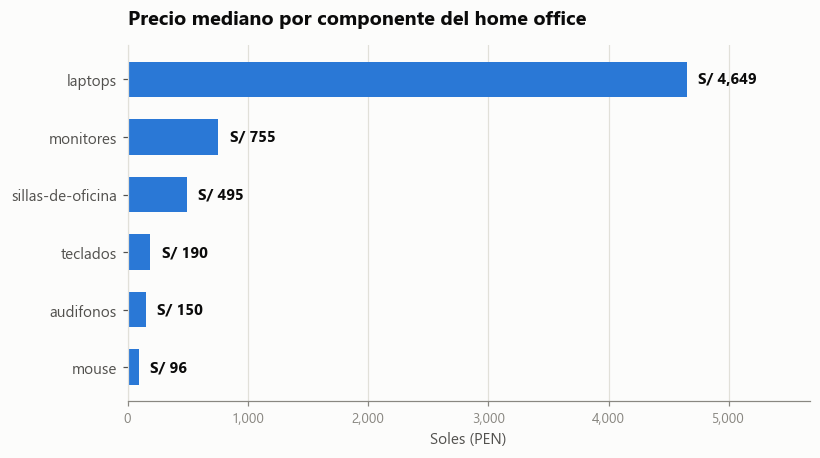

In [38]:
datos = resumen.sort_values('mediana')
fig, ax = plt.subplots(figsize=(8, 4.2))
barras = ax.barh(datos.index, datos['mediana'], color=AZUL, height=0.62)

for barra, valor in zip(barras, datos['mediana']):
    ax.text(barra.get_width() + datos['mediana'].max() * 0.02, barra.get_y() + barra.get_height() / 2,
            f'S/ {valor:,.0f}', va='center', fontsize=10, color=TINTA, fontweight='bold')

ax.set_title('Precio mediano por componente del home office')
ax.set_xlabel('Soles (PEN)')
ax.set_xlim(0, datos['mediana'].max() * 1.22)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.grid(True); ax.yaxis.grid(False); ax.set_axisbelow(True)
ax.spines['left'].set_color(REJILLA)
guardar(fig, 'precio_mediano_por_categoria.png')
plt.show()

Gráfico guardado: c:\Users\yared\Documents\ACD\sem6\EC1-scraping\ec1-scraping-mercadolibre\graficos\dispersion_precios.png


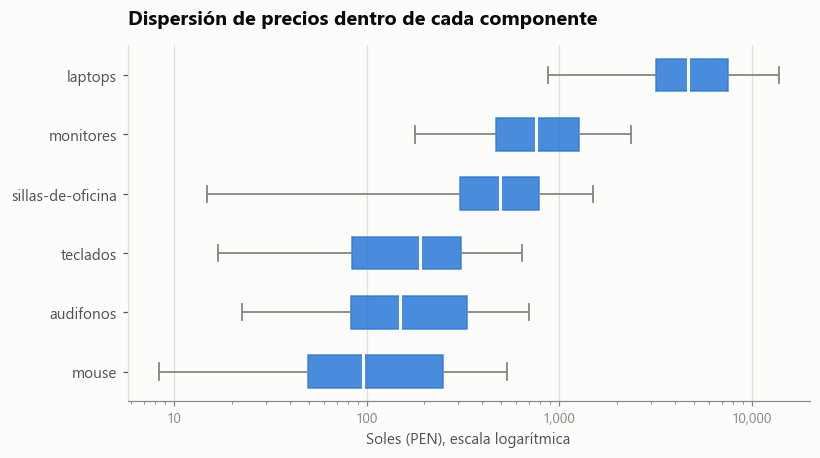

In [39]:
orden = resumen.sort_values('mediana').index.tolist()
series = [limpio.loc[limpio['categoria'] == c, 'precio'].values for c in orden]

fig, ax = plt.subplots(figsize=(8, 4.2))
caja = ax.boxplot(series, vert=False, labels=orden, widths=0.55, showfliers=False,
                  patch_artist=True, medianprops={'color': FONDO, 'linewidth': 2})
for cuerpo in caja['boxes']:
    cuerpo.set(facecolor=AZUL, edgecolor=AZUL, alpha=0.85)
for pieza in caja['whiskers'] + caja['caps']:
    pieza.set(color=TENUE, linewidth=1.2)

ax.set_xscale('log')
ax.set_title('Dispersión de precios dentro de cada componente')
ax.set_xlabel('Soles (PEN), escala logarítmica')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines['left'].set_color(REJILLA)
guardar(fig, 'dispersion_precios.png')
plt.show()

Gráfico guardado: c:\Users\yared\Documents\ACD\sem6\EC1-scraping\ec1-scraping-mercadolibre\graficos\cobertura_cuotas.png


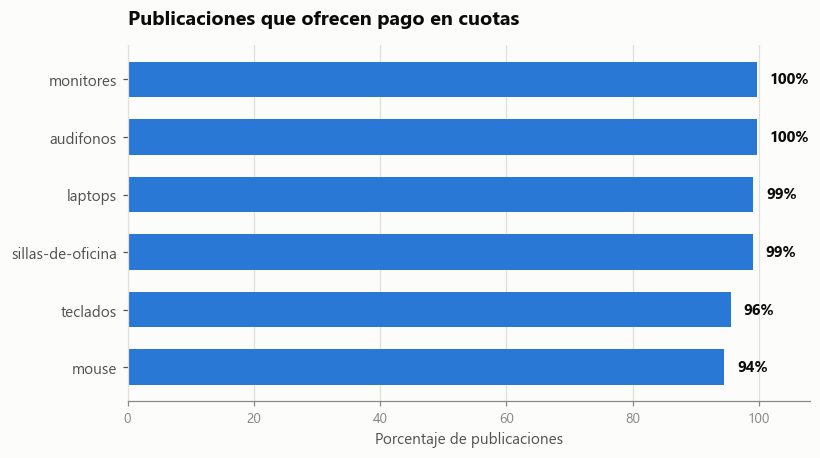

In [40]:
cuotas = (limpio.groupby('categoria')['ofrece_cuotas'].mean().mul(100)
          .round(1).sort_values())

fig, ax = plt.subplots(figsize=(8, 4.2))
barras = ax.barh(cuotas.index, cuotas.values, color=AZUL, height=0.62)
for barra, valor in zip(barras, cuotas.values):
    ax.text(barra.get_width() + 2, barra.get_y() + barra.get_height() / 2,
            f'{valor:.0f}%', va='center', fontsize=10, color=TINTA, fontweight='bold')

ax.set_title('Publicaciones que ofrecen pago en cuotas')
ax.set_xlabel('Porcentaje de publicaciones')
ax.set_xlim(0, 108)
ax.xaxis.grid(True); ax.yaxis.grid(False); ax.set_axisbelow(True)
ax.spines['left'].set_color(REJILLA)
guardar(fig, 'cobertura_cuotas.png')
plt.show()

## 12. Conclusiones y limitaciones

**Conclusiones**

1. Armar un *home office* completo en Mercado Libre Perú cuesta, en la mediana, el monto
   reportado arriba; la laptop concentra la mayor parte del presupuesto.
2. La dispersión de precios dentro de una misma categoría es de varios órdenes de magnitud:
   la categoría es la *búsqueda de origen*, no una clase de producto homogénea, y arrastra
   accesorios y repuestos junto al producto principal.
3. El financiamiento en cuotas está muy extendido, lo que sugiere que el precio de lista no es
   el único factor de decisión del comprador peruano.

**Limitaciones**

- La muestra proviene de páginas de resultados ordenadas por relevancia: **no es aleatoria ni
  representativa** de todo el catálogo ni del mercado peruano.
- Son **precios de oferta publicados, no transacciones**: nada garantiza que alguien haya
  comprado a ese precio.
- Es un **corte transversal de un día**; no permite conclusiones sobre evolución de precios.
- Los campos de vendedor, envío y reseñas dependen de la plantilla que Mercado Libre sirva en
  cada tarjeta, por lo que su cobertura es parcial (ver la tabla de diagnóstico).
- No se abrieron las fichas de producto, de modo que no hay marca, condición ni reputación
  verificada del vendedor.

---

### Cómo exportar este notebook a PDF

Ejecuta el notebook completo de principio a fin y luego:

- **Google Colab:** `Archivo > Imprimir > Guardar como PDF`.
- **VS Code / Jupyter:** `File > Export > PDF`, o desde la terminal:
  `jupyter nbconvert --to webpdf EC1_scraping_mercadolibre.ipynb`